# Multi-Class Text Sentiment Classifier
Steps: data -> clean (stop-words + lemmatization) -> TF-IDF -> model -> F1-score

Classes: negative / neutral / positive (tweets, TweetEval sentiment dataset)

In [1]:
# !pip install scikit-learn nltk pandas datasets matplotlib
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## 1. Data load

In [ ]:
#  0 = negative, 1 = neutral, 2 = positive

ds = load_dataset("cardiffnlp/tweet_eval", "sentiment", split="train")
ds = ds.shuffle(seed=42).select(range(20000))   # 20k samples
class_names = ["negative", "neutral", "positive"]

texts = ds["text"]
labels = ds["label"]
print(len(texts), "tweets")

20000 tweets


## 2. Preprocessing: remove stop-words + lemmatization

In [11]:
stop_words = set(stopwords.words("english")) - {"not", "no", "nor"} 
lemmatizer = WordNetLemmatizer()

def clean(text):
    text = text.lower().replace("n't", " not")               # "don't" -> "do not"
    text = re.sub(r"@\w+|http\S+", " ", text)               # remove mentions and links
    text = re.sub(r"[^a-z\s]", " ", text)                   # keep letters only
    words = [w for w in text.split() if w not in stop_words]  # remove stop-words
    words = [lemmatizer.lemmatize(w) for w in words]          # cars -> car
    return " ".join(words)

texts = [clean(t) for t in texts]

## 3. TF-IDF + Train/Test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

## 4. Model train + F1-score

In [13]:
model = LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("F1 (macro):", f1_score(y_test, pred, average="macro"))
print(classification_report(y_test, pred, target_names=class_names))

F1 (macro): 0.5962460883065482
              precision    recall  f1-score   support

    negative       0.43      0.58      0.49       621
     neutral       0.66      0.62      0.64      1854
    positive       0.68      0.64      0.66      1525

    accuracy                           0.62      4000
   macro avg       0.59      0.61      0.60      4000
weighted avg       0.63      0.62      0.62      4000



## 5. Predict on new text

In [14]:
new = ["I love this phone, the battery is amazing", 
       "This was the worst service ever, I am so angry",
        "The meeting is scheduled for 3 pm tomorrow"
        ]

print(model.predict(tfidf.transform([clean(t) for t in new])))
print(class_names)

[2 0 1]
['negative', 'neutral', 'positive']


---
#  Evaluation
This part reuses the same data, TF-IDF and model from old code and adds confusion matrix.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.cluster import KMeans

## 6. Comparing three models (F1-score)

In [16]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "LinearSVC": LinearSVC(),
    "MultinomialNB": MultinomialNB(),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"model": name,
                 "F1 macro": f1_score(y_test, p, average="macro"),
                 "F1 weighted": f1_score(y_test, p, average="weighted")})
    
pd.DataFrame(rows).sort_values("F1 macro", ascending=False).round(4)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


,model,F1 macro,F1 weighted
1,LinearSVC,0.5685,0.6091
0,LogisticRegression,0.5526,0.6117
2,MultinomialNB,0.4368,0.5448


## 7. Confusion Matrix

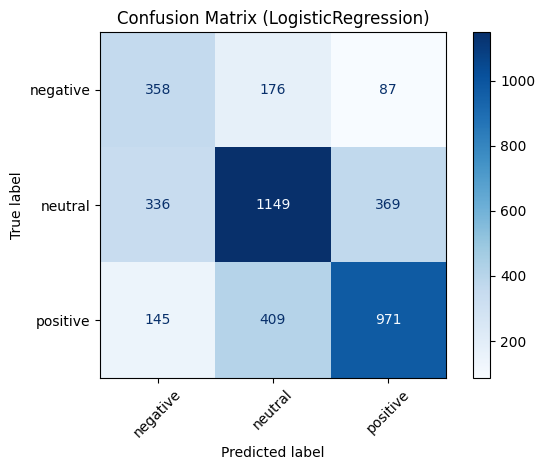

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, 
    display_labels=class_names, 
    cmap="Blues", 
    xticks_rotation=45
    )

plt.title("Confusion Matrix (LogisticRegression)")
plt.tight_layout()
plt.show()